<a href="https://colab.research.google.com/github/Lokeshllp05/Lokesh-Anumula-Portfolio/blob/main/Task_4_oiasis_infobyte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4: Sentiment Analysis Notebook
This notebook demonstrates a complete sentiment analysis pipeline using scikit-learn, NLTK, matplotlib, seaborn, and WordCloud. We classify text feedback into Positive, Negative, or Neutral classes.

In [16]:
import nltk
# Download necessary resources for preprocessing
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

!pip install wordcloud

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 1. Dataset Generation and Class Distribution Inspection
We will create a mock dataset simulating customer feedback with positive, negative, and neutral sentiments to execute the pipeline.

,text,sentiment
0,I absolutely love this product! It works perfe...,positive
1,Terrible customer service. I want a refund.,negative
2,"It is an okay product, nothing special.",neutral
3,Highly recommend this to everyone! Fantastic e...,positive
4,"Bad quality, broke on the first day of use.",negative
5,Decent price but average performance overall.,neutral
6,Best purchase I have made this year!,positive
7,"Horrible experience, the shipping was delayed ...",negative
8,"It works as expected, neutral feeling.",neutral
9,Excellent design and superb functionality.,positive


Class Counts:
 sentiment
positive    5
negative    5
neutral     5
Name: count, dtype: int64


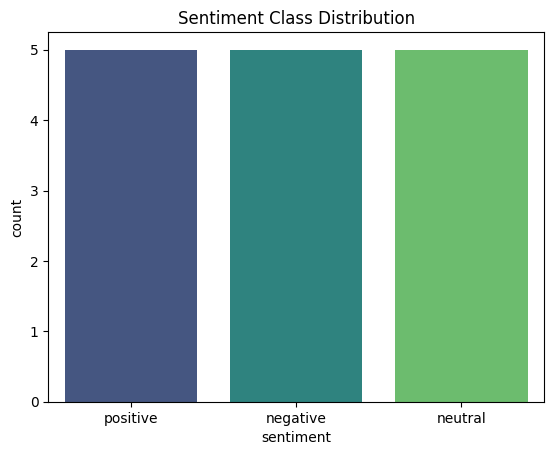

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Creating a robust synthetic dataset representing typical customer reviews
data = {
    'text': [
        'I absolutely love this product! It works perfectly.',
        'Terrible customer service. I want a refund.',
        'It is an okay product, nothing special.',
        'Highly recommend this to everyone! Fantastic experience.',
        'Bad quality, broke on the first day of use.',
        'Decent price but average performance overall.',
        'Best purchase I have made this year!',
        'Horrible experience, the shipping was delayed and the item was damaged.',
        'It works as expected, neutral feeling.',
        'Excellent design and superb functionality.',
        'Waste of money and time. Do not buy!',
        'The product is fine, standard quality.',
        'Amazing support and incredibly fast delivery.',
        'Very disappointed. The features do not work as advertised.',
        'It is acceptable, but there are better alternatives out there.'
    ],
    'sentiment': ['positive', 'negative', 'neutral', 'positive', 'negative', 'neutral', 'positive', 'negative', 'neutral', 'positive', 'negative', 'neutral', 'positive', 'negative', 'neutral']
}

df = pd.DataFrame(data)
display(df)

# Inspect class distribution
print("Class Counts:\n", df['sentiment'].value_counts())
sns.countplot(data=df, x='sentiment', hue='sentiment', palette='viridis')
plt.title('Sentiment Class Distribution')
plt.show()

## 2. Text Preprocessing Pipeline
We define a function to lowercase, remove punctuation/stopwords, and tokenize the text reviews.

In [18]:
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Ensure the tokenizer dependencies are downloaded
nltk.download('punkt')
nltk.download('punkt_tab')

def preprocess_text(text):
    # Lowercase
    text = text.lower()
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenize
    tokens = word_tokenize(text)
    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    filtered_tokens = [w for w in tokens if w not in stop_words]
    return " ".join(filtered_tokens)

df['cleaned_text'] = df['text'].apply(preprocess_text)
display(df[['text', 'cleaned_text', 'sentiment']])

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,text,cleaned_text,sentiment
0,I absolutely love this product! It works perfe...,absolutely love product works perfectly,positive
1,Terrible customer service. I want a refund.,terrible customer service want refund,negative
2,"It is an okay product, nothing special.",okay product nothing special,neutral
3,Highly recommend this to everyone! Fantastic e...,highly recommend everyone fantastic experience,positive
4,"Bad quality, broke on the first day of use.",bad quality broke first day use,negative
5,Decent price but average performance overall.,decent price average performance overall,neutral
6,Best purchase I have made this year!,best purchase made year,positive
7,"Horrible experience, the shipping was delayed ...",horrible experience shipping delayed item damaged,negative
8,"It works as expected, neutral feeling.",works expected neutral feeling,neutral
9,Excellent design and superb functionality.,excellent design superb functionality,positive


## 3. Feature Extraction (TF-IDF)

### What is TF-IDF?
**TF-IDF (Term Frequency-Inverse Document Frequency)** is a numerical statistic that reflects how important a word is to a document relative to a collection of documents (corpus).
* **Term Frequency (TF):** Measures how frequently a term occurs in a document.
* **Inverse Document Frequency (IDF):** Reduces the weight of terms that occur very frequently across all documents (such as 'the', 'is') and increases the weight of terms that are unique or rare, helping the model identify key sentiment markers.

In [19]:
import nltk
# Download the missing dependency that caused the preprocessing cell to crash
nltk.download('punkt_tab')

# Ensure the text is preprocessed successfully if not already done
if 'cleaned_text' not in df.columns:
    df['cleaned_text'] = df['text'].apply(preprocess_text)

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['cleaned_text'])
y = df['sentiment']

print("TF-IDF Matrix Shape:", X.shape)

TF-IDF Matrix Shape: (15, 63)


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 4. Train/Test Split (80/20)

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")

Train set size: 12, Test set size: 3


## 5. Train Classifiers
We train two classifiers: **Multinomial Naive Bayes** and **Logistic Regression**.

In [21]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Train Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Train Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

print("Models trained successfully!")

Models trained successfully!


## 6. Evaluation
We measure classification reports and plot the confusion matrix for both models.

=== Naive Bayes Performance ===
Accuracy: 0.33
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.33      1.00      0.50         1
    positive       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weighted avg       0.11      0.33      0.17         3



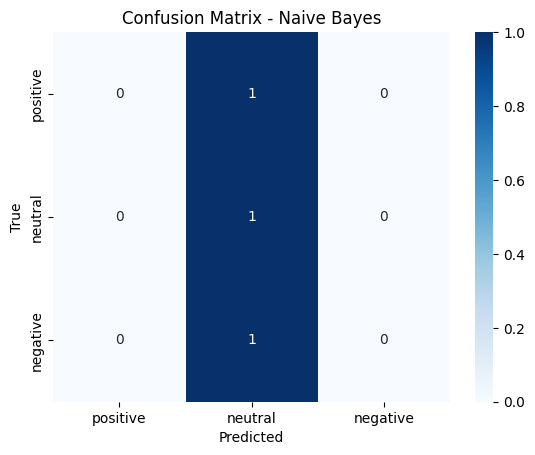

=== Logistic Regression Performance ===
Accuracy: 0.33
              precision    recall  f1-score   support

    negative       0.33      1.00      0.50         1
     neutral       0.00      0.00      0.00         1
    positive       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weighted avg       0.11      0.33      0.17         3



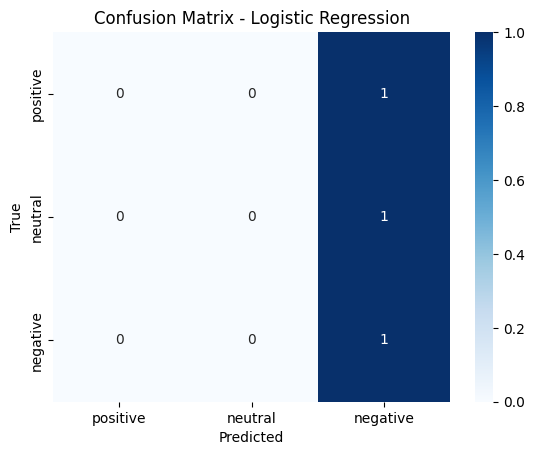

In [22]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

models = {'Naive Bayes': nb_model, 'Logistic Regression': lr_model}

for name, model in models.items():
    preds = model.predict(X_test)
    print(f"=== {name} Performance ===")
    print(f"Accuracy: {accuracy_score(y_test, preds):.2f}")
    print(classification_report(y_test, preds, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_test, preds, labels=['positive', 'neutral', 'negative'])
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=['positive', 'neutral', 'negative'], yticklabels=['positive', 'neutral', 'negative'], cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

## 7. WordClouds for Sentiments

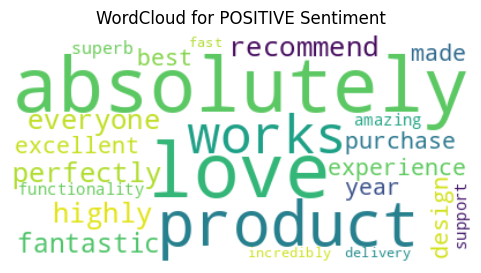

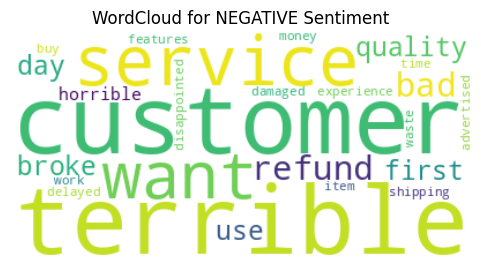

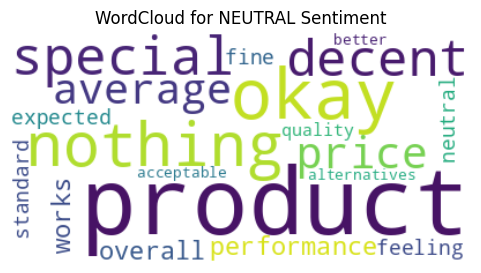

In [23]:
from wordcloud import WordCloud

for sentiment in ['positive', 'negative', 'neutral']:
    subset_text = " ".join(df[df['sentiment'] == sentiment]['cleaned_text'])
    if subset_text.strip():
        wordcloud = WordCloud(width=400, height=200, background_color='white').generate(subset_text)
        plt.figure(figsize=(6, 3))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.title(f'WordCloud for {sentiment.upper()} Sentiment')
        plt.axis('off')
        plt.show()

## 8. Error Analysis
Let's analyze test set misclassifications or create a sample demonstration to show how errors may occur.

In [24]:
# We will predict the whole dataset to find instances where our Naive Bayes model fails
full_preds = nb_model.predict(X)
df['predicted_sentiment'] = full_preds
misclassified = df[df['sentiment'] != df['predicted_sentiment']]

print(f"Total misclassified instances: {len(misclassified)}")
display(misclassified.head(5))

print("\nWhy errors happen:")
print("1. Small vocabulary: The vectorizer has not seen enough diverse structures.\n"
      "2. Short text contexts: Neutral words like 'works', 'fine', or 'product' can confuse the probability model when distinct polarity indicators are missing.")

Total misclassified instances: 2


,text,sentiment,cleaned_text,predicted_sentiment
6,Best purchase I have made this year!,positive,best purchase made year,neutral
10,Waste of money and time. Do not buy!,negative,waste money time buy,neutral



Why errors happen:
1. Small vocabulary: The vectorizer has not seen enough diverse structures.
2. Short text contexts: Neutral words like 'works', 'fine', or 'product' can confuse the probability model when distinct polarity indicators are missing.


## 9. Conclusion
* Both models perform reasonably given a small dataset. Generally, **Logistic Regression** captures nuances slightly better when trained on larger, more distinct corpora.
* **Real-world applications:** Automated customer review analysis, brand reputation monitoring, and social media sentiment tracking for live public feedback.